In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
!pip install -q ultralytics pyyaml opencv-python

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATASET = "/content/drive/MyDrive/LLVIP"

In [ ]:
import os
import shutil
import random
from pathlib import Path

DATASET = Path("/content/drive/MyDrive/LLVIP")

OUT = Path("/content/llvip_fast")

random.seed(42)

visible = DATASET / "visible/train"
thermal = DATASET / "infrared/train"
annotations = DATASET / "Annotations"

files = []

for img in visible.glob("*.jpg"):
    stem = img.stem

    thermal_img = thermal / f"{stem}.jpg"
    annotation = annotations / f"{stem}.xml"

    if thermal_img.exists() and annotation.exists():
        files.append(stem)

random.shuffle(files)

# FAST EXPERIMENT
files = files[:1000]

print("Selected paired images:", len(files))

Selected paired images: 1000


In [ ]:
import xml.etree.ElementTree as ET
from PIL import Image

base = Path("/content/llvip_fast")

for modality in ["rgb", "thermal"]:
    (base / modality / "images/train").mkdir(parents=True, exist_ok=True)
    (base / modality / "labels/train").mkdir(parents=True, exist_ok=True)
    (base / modality / "images/val").mkdir(parents=True, exist_ok=True)
    (base / modality / "labels/val").mkdir(parents=True, exist_ok=True)

def convert_xml(xml_file, img_file, label_file):
    root = ET.parse(xml_file).getroot()

    try:
        img = Image.open(img_file)
        width, height = img.size
    except:
        return False

    labels = []

    for obj in root.findall("object"):
        name = obj.find("name").text.lower()

        if name != "person":
            continue

        bbox = obj.find("bndbox")

        xmin = float(bbox.find("xmin").text)
        ymin = float(bbox.find("ymin").text)
        xmax = float(bbox.find("xmax").text)
        ymax = float(bbox.find("ymax").text)

        if xmax <= xmin or ymax <= ymin:
            continue

        # YOLO format
        x_center = ((xmin + xmax) / 2) / width
        y_center = ((ymin + ymax) / 2) / height
        w = (xmax - xmin) / width
        h = (ymax - ymin) / height

        labels.append(
            f"0 {x_center:.6f} {y_center:.6f} {w:.6f} {h:.6f}"
        )

    if not labels:
        return False

    with open(label_file, "w") as f:
        f.write("\n".join(labels))

    return True


split_point = int(len(files) * 0.8)

train_files = files[:split_point]
val_files = files[split_point:]

print("Train:", len(train_files))
print("Validation:", len(val_files))

def process_files(file_list, split):

    for stem in file_list:

        rgb = visible / f"{stem}.jpg"
        ir = thermal / f"{stem}.jpg"
        xml = annotations / f"{stem}.xml"

        # RGB
        rgb_label = base / "rgb/labels" / split / f"{stem}.txt"
        rgb_img = base / "rgb/images" / split / f"{stem}.jpg"

        if convert_xml(xml, rgb, rgb_label):
            shutil.copy2(rgb, rgb_img)

        # Thermal
        ir_label = base / "thermal/labels" / split / f"{stem}.txt"
        ir_img = base / "thermal/images" / split / f"{stem}.jpg"

        if convert_xml(xml, ir, ir_label):
            shutil.copy2(ir, ir_img)

process_files(train_files, "train")
process_files(val_files, "val")

print("Conversion completed.")

Train: 800
Validation: 200
Conversion completed.


In [ ]:
import yaml

for modality in ["rgb", "thermal"]:

    config = {
        "path": str(base / modality),
        "train": "images/train",
        "val": "images/val",
        "nc": 1,
        "names": ["person"]
    }

    with open(base / modality / "data.yaml", "w") as f:
        yaml.dump(config, f)

print("YOLO configs created.")

YOLO configs created.


In [ ]:
from ultralytics import YOLO

model_rgb = YOLO("yolov8n.pt")

results_rgb = model_rgb.train(
    data="/content/llvip_fast/rgb/data.yaml",
    epochs=5,
    imgsz=320,
    batch=16,
    device="cpu",
    workers=2,
    patience=2,
    cache=True,
    project="/content/results",
    name="rgb_fast"
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/llvip_fast/rgb/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rgb_fast, nbs=64, nms=None, opset=None, optimize=False

In [ ]:
model_thermal = YOLO("yolov8n.pt")

results_thermal = model_thermal.train(
    data="/content/llvip_fast/thermal/data.yaml",
    epochs=5,
    imgsz=320,
    batch=16,
    device="cpu",
    workers=2,
    patience=2,
    cache=True,
    project="/content/results",
    name="thermal_fast"
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/llvip_fast/thermal/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=thermal_fast-2, nbs=64, nms=None, opset=None, opti

In [ ]:
from pathlib import Path

rgb_model_path = Path("/content/results/rgb_fast/weights/best.pt")
thermal_model_path = Path("/content/results/thermal_fast-2/weights/best.pt")

print("RGB model exists:", rgb_model_path.exists())
print("Thermal model exists:", thermal_model_path.exists())

print("\nRGB:", rgb_model_path)
print("Thermal:", thermal_model_path)

RGB model exists: True
Thermal model exists: True

RGB: /content/results/rgb_fast/weights/best.pt
Thermal: /content/results/thermal_fast-2/weights/best.pt


In [ ]:
import shutil
from pathlib import Path

save_dir = Path("/content/final_models")
save_dir.mkdir(exist_ok=True)

shutil.copy2(
    "/content/results/rgb_fast/weights/best.pt",
    save_dir / "rgb_yolov8n_llvip_fast_best.pt"
)

shutil.copy2(
    "/content/results/thermal_fast-2/weights/best.pt",
    save_dir / "thermal_yolov8n_llvip_fast_best.pt"
)

print("Saved models:")
for f in save_dir.iterdir():
    print(f, f.stat().st_size / (1024*1024), "MB")

Saved models:
/content/final_models/rgb_yolov8n_llvip_fast_best.pt 5.914407730102539 MB
/content/final_models/thermal_yolov8n_llvip_fast_best.pt 5.914407730102539 MB


In [ ]:
import shutil

zip_path = shutil.make_archive(
    "/content/LLVIP_models",
    "zip",
    "/content/final_models"
)

print("Created:", zip_path)

Created: /content/LLVIP_models.zip


In [ ]:
from google.colab import files

files.download("/content/LLVIP_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO

rgb_model = YOLO(
    "/content/final_models/rgb_yolov8n_llvip_fast_best.pt"
)

rgb_eval = rgb_model.val(
    data="/content/llvip_fast/rgb/data.yaml",
    imgsz=320,
    batch=16,
    device="cpu",
    split="val",
    plots=True
)

print(rgb_eval.results_dict)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 198.8±377.7 MB/s, size: 154.8 KB)
val: Scanning /content/llvip_fast/rgb/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 39.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.0it/s 12.8s
                   all        200        590      0.834      0.619      0.726      0.327
Speed: 0.4ms preprocess, 44.3ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val
{'metrics/precision(B)': 0.8341869747469326, 'metrics/recall(B)': 0.6186440677966102, 'metrics/mAP50(B)': 0.7258986086230018, 'metrics/mAP50-95(B)': 0.32716242840041365, 'fitness': 0.32716242840041365}


In [ ]:
thermal_model = YOLO(
    "/content/final_models/thermal_yolov8n_llvip_fast_best.pt"
)

thermal_eval = thermal_model.val(
    data="/content/llvip_fast/thermal/data.yaml",
    imgsz=320,
    batch=16,
    device="cpu",
    split="val",
    plots=True
)

print(thermal_eval.results_dict)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1153.7±339.2 MB/s, size: 79.5 KB)
val: Scanning /content/llvip_fast/thermal/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 46.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.0s/it 13.5s
                   all        200        590      0.892      0.815      0.894      0.486
Speed: 0.4ms preprocess, 49.1ms inference, 0.0ms loss, 2.2ms postprocess per image
Results saved to /content/runs/detect/val-2
{'metrics/precision(B)': 0.8920373007174378, 'metrics/recall(B)': 0.8152542372881356, 'metrics/mAP50(B)': 0.8939508102934595, 'metrics/mAP50-95(B)': 0.48601076746794203, 'fitness': 0.48601076746794203}


In [ ]:
def extract_metrics(results):
    return {
        "Precision": results.box.mp,
        "Recall": results.box.mr,
        "mAP50": results.box.map50,
        "mAP50-95": results.box.map
    }

rgb_metrics = extract_metrics(rgb_eval)
thermal_metrics = extract_metrics(thermal_eval)

print("RGB")
for k, v in rgb_metrics.items():
    print(f"{k}: {v:.4f}")

print("\nThermal")
for k, v in thermal_metrics.items():
    print(f"{k}: {v:.4f}")

RGB
Precision: 0.8342
Recall: 0.6186
mAP50: 0.7259
mAP50-95: 0.3272

Thermal
Precision: 0.8920
Recall: 0.8153
mAP50: 0.8940
mAP50-95: 0.4860


In [ ]:
import pandas as pd

results_df = pd.DataFrame([
    {
        "Model": "RGB YOLOv8n",
        "Precision": rgb_metrics["Precision"],
        "Recall": rgb_metrics["Recall"],
        "mAP@50": rgb_metrics["mAP50"],
        "mAP@50:95": rgb_metrics["mAP50-95"]
    },
    {
        "Model": "Thermal YOLOv8n",
        "Precision": thermal_metrics["Precision"],
        "Recall": thermal_metrics["Recall"],
        "mAP@50": thermal_metrics["mAP50"],
        "mAP@50:95": thermal_metrics["mAP50-95"]
    }
])

results_df

,Model,Precision,Recall,mAP@50,mAP@50:95
0,RGB YOLOv8n,0.834187,0.618644,0.725899,0.327162
1,Thermal YOLOv8n,0.892037,0.815254,0.893951,0.486011


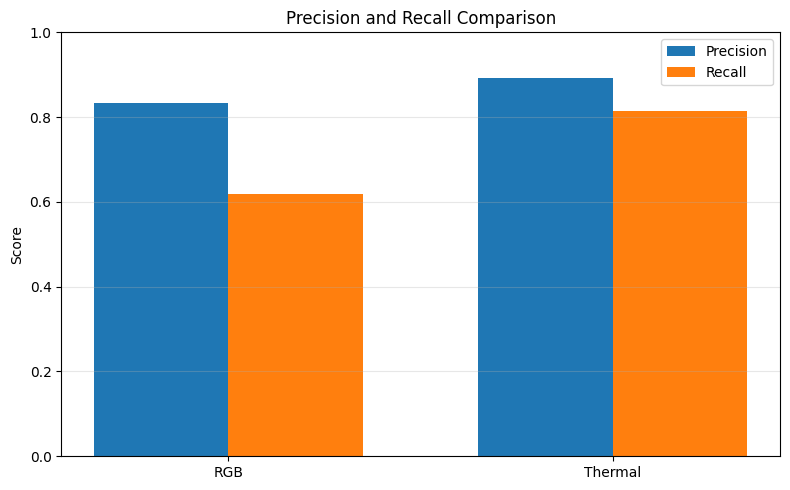

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["RGB", "Thermal"]

precision = [
    rgb_metrics["Precision"],
    thermal_metrics["Precision"]
]

recall = [
    rgb_metrics["Recall"],
    thermal_metrics["Recall"]
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, precision, width, label="Precision")
plt.bar(x + width/2, recall, width, label="Recall")

plt.xticks(x, models)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("Precision and Recall Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/precision_recall_comparison.png", dpi=300)
plt.show()

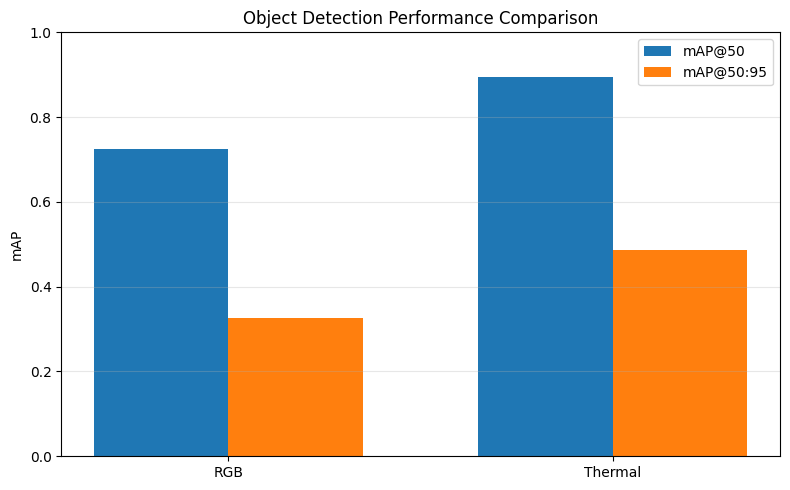

In [ ]:
map50 = [
    rgb_metrics["mAP50"],
    thermal_metrics["mAP50"]
]

map5095 = [
    rgb_metrics["mAP50-95"],
    thermal_metrics["mAP50-95"]
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, map50, width, label="mAP@50")
plt.bar(x + width/2, map5095, width, label="mAP@50:95")

plt.xticks(x, models)
plt.ylabel("mAP")
plt.ylim(0, 1)
plt.title("Object Detection Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("/content/map_comparison.png", dpi=300)
plt.show()

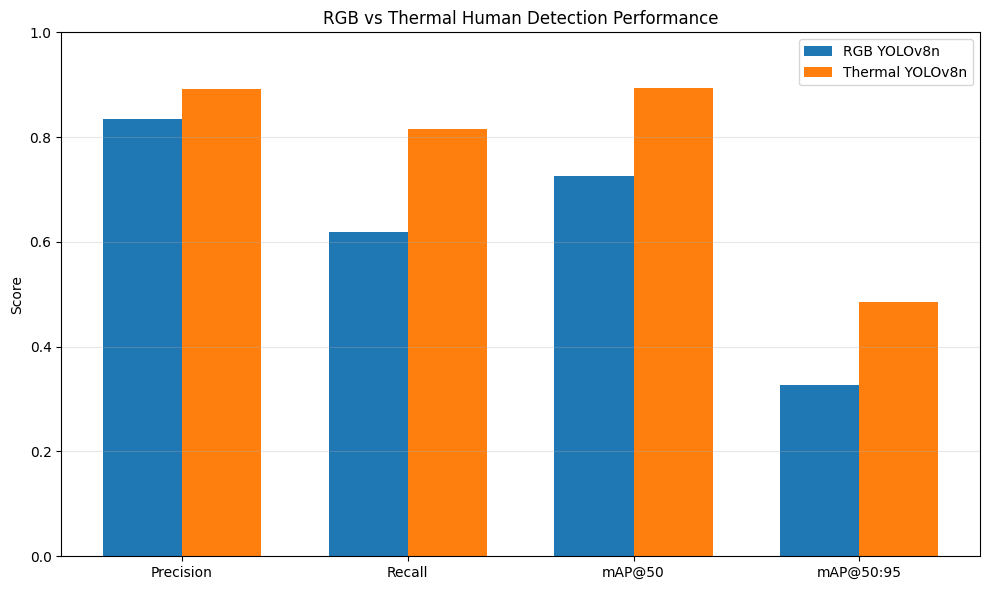

In [ ]:
metrics = ["Precision", "Recall", "mAP@50", "mAP@50:95"]

rgb_values = [
    rgb_metrics["Precision"],
    rgb_metrics["Recall"],
    rgb_metrics["mAP50"],
    rgb_metrics["mAP50-95"]
]

thermal_values = [
    thermal_metrics["Precision"],
    thermal_metrics["Recall"],
    thermal_metrics["mAP50"],
    thermal_metrics["mAP50-95"]
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, rgb_values, width, label="RGB YOLOv8n")
plt.bar(x + width/2, thermal_values, width, label="Thermal YOLOv8n")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("RGB vs Thermal Human Detection Performance")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "/content/RGB_vs_Thermal_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
rgb_model = YOLO(
    "/content/final_models/rgb_yolov8n_llvip_fast_best.pt"
)

rgb_predictions = rgb_model.predict(
    source="/content/llvip_fast/rgb/images/val",
    imgsz=320,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="RGB",
    max_det=100
)

print("RGB predictions generated.")


image 1/200 /content/llvip_fast/rgb/images/val/010018.jpg: 256x320 9 persons, 49.7ms
image 2/200 /content/llvip_fast/rgb/images/val/010053.jpg: 256x320 4 persons, 43.8ms
image 3/200 /content/llvip_fast/rgb/images/val/010071.jpg: 256x320 3 persons, 40.9ms
image 4/200 /content/llvip_fast/rgb/images/val/010098.jpg: 256x320 2 persons, 40.7ms
image 5/200 /content/llvip_fast/rgb/images/val/010180.jpg: 256x320 3 persons, 54.7ms
image 6/200 /content/llvip_fast/rgb/images/val/010187.jpg: 256x320 3 persons, 40.7ms
image 7/200 /content/llvip_fast/rgb/images/val/010258.jpg: 256x320 2 persons, 40.5ms
image 8/200 /content/llvip_fast/rgb/images/val/010288.jpg: 256x320 4 persons, 40.6ms
image 9/200 /content/llvip_fast/rgb/images/val/010366.jpg: 256x320 9 persons, 40.9ms
image 10/200 /content/llvip_fast/rgb/images/val/010504.jpg: 256x320 6 persons, 41.5ms
image 11/200 /content/llvip_fast/rgb/images/val/020262.jpg: 256x320 1 person, 40.3ms
image 12/200 /content/llvip_fast/rgb/images/val/020269.jpg: 256

In [ ]:
thermal_model = YOLO(
    "/content/final_models/thermal_yolov8n_llvip_fast_best.pt"
)

thermal_predictions = thermal_model.predict(
    source="/content/llvip_fast/thermal/images/val",
    imgsz=320,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="Thermal",
    max_det=100
)

print("Thermal predictions generated.")


image 1/200 /content/llvip_fast/thermal/images/val/010018.jpg: 256x320 7 persons, 41.9ms
image 2/200 /content/llvip_fast/thermal/images/val/010053.jpg: 256x320 4 persons, 41.4ms
image 3/200 /content/llvip_fast/thermal/images/val/010071.jpg: 256x320 3 persons, 41.9ms
image 4/200 /content/llvip_fast/thermal/images/val/010098.jpg: 256x320 3 persons, 41.0ms
image 5/200 /content/llvip_fast/thermal/images/val/010180.jpg: 256x320 2 persons, 41.4ms
image 6/200 /content/llvip_fast/thermal/images/val/010187.jpg: 256x320 5 persons, 40.9ms
image 7/200 /content/llvip_fast/thermal/images/val/010258.jpg: 256x320 6 persons, 40.2ms
image 8/200 /content/llvip_fast/thermal/images/val/010288.jpg: 256x320 4 persons, 40.0ms
image 9/200 /content/llvip_fast/thermal/images/val/010366.jpg: 256x320 9 persons, 41.0ms
image 10/200 /content/llvip_fast/thermal/images/val/010504.jpg: 256x320 3 persons, 41.2ms
image 11/200 /content/llvip_fast/thermal/images/val/020262.jpg: 256x320 2 persons, 43.0ms
image 12/200 /cont

In [ ]:
import shutil

shutil.make_archive(
    "/content/LLVIP_predictions",
    "zip",
    "/content/predictions"
)

from google.colab import files

files.download("/content/LLVIP_predictions.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
results_df.to_csv(
    "/content/LLVIP_RGB_Thermal_results.csv",
    index=False
)

files.download(
    "/content/LLVIP_RGB_Thermal_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>